In [ ]:
# ============================================================
# NOTEBOOK 01 — EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================
# WHAT IS THIS PROJECT?
# NewsLens is a publishing intelligence pipeline that:
# 1. Classifies news articles by topic (NLP)
# 2. Predicts which readers will churn (ML)
# 3. Recommends articles to re-engage readers
#
# This mirrors exactly what Upscore does for media houses
# like Stern, Heise and Rhein-Zeitung.
#
# WHAT IS THIS NOTEBOOK?
# Before building anything we explore the dataset.
# We use the UCI News Aggregator Dataset:
# - 422,937 real news articles
# - 4 categories: Business, Science/Tech, Entertainment, Health
# - Loaded directly via Python — no download needed!
#
# WHAT WE WILL LEARN:
# - Shape and structure of the data
# - Distribution of categories
# - Most common words per category
# - Data quality issues to fix
# ============================================================

print("Starting EDA notebook...")
print("Dataset: UCI News Aggregator — 422,937 articles")

In [1]:
# pandas for data manipulation
import pandas as pd

# numpy for numerical operations
import numpy as np

# matplotlib and seaborn for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# ucimlrepo fetches the dataset directly from UCI
# no manual download needed!
from ucimlrepo import fetch_ucirepo

# re for text cleaning with regular expressions
import re

# Set plot style — makes charts look professional
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported!")

Libraries imported!


In [3]:
# ============================================================
# STEP 1: LOAD THE DATASET FROM CSV
# ============================================================
# The UCI News Aggregator dataset has no header row
# so we define the column names manually based on readme.txt
# Columns: ID, TITLE, URL, PUBLISHER, CATEGORY, STORY, HOSTNAME, TIMESTAMP

import pandas as pd

# Define column names manually — dataset has no header
col_names = [
    "ID",        # unique article ID
    "TITLE",     # article headline — this is our main text feature
    "URL",       # full URL of the article
    "PUBLISHER", # who published it
    "CATEGORY",  # b=Business, t=Tech, e=Entertainment, m=Health
    "STORY",     # story cluster ID
    "HOSTNAME",  # website hostname
    "TIMESTAMP"  # publication timestamp
]

# Load the CSV with tab separator and our column names
df = pd.read_csv(
    "../data/processed/newsCorpora.csv",
    sep="\t",           # tab separated file
    names=col_names,    # our custom column names
    encoding="utf-8"    # handle special characters
)

print(f"Dataset loaded!")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Dataset loaded!
Shape: 422,419 rows x 8 columns


,ID,TITLE,URL,PUBLISHER,CATEGORY,STORY,HOSTNAME,TIMESTAMP
0,1,"Fed official says weak data caused by weather,...",http://www.latimes.com/business/money/la-fi-mo...,Los Angeles Times,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.latimes.com,1394470370698
1,2,Fed's Charles Plosser sees high bar for change...,http://www.livemint.com/Politics/H2EvwJSK2VE6O...,Livemint,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.livemint.com,1394470371207
2,3,US open: Stocks fall after Fed official hints ...,http://www.ifamagazine.com/news/us-open-stocks...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371550
3,4,"Fed risks falling 'behind the curve', Charles ...",http://www.ifamagazine.com/news/fed-risks-fall...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371793
4,5,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,http://www.moneynews.com/Economy/federal-reser...,Moneynews,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.moneynews.com,1394470372027


In [4]:
# ============================================================
# STEP 2: FIRST LOOK AT THE DATA
# ============================================================

print("=== FIRST 5 ROWS ===")
display(df.head())

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

=== FIRST 5 ROWS ===


,ID,TITLE,URL,PUBLISHER,CATEGORY,STORY,HOSTNAME,TIMESTAMP
0,1,"Fed official says weak data caused by weather,...",http://www.latimes.com/business/money/la-fi-mo...,Los Angeles Times,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.latimes.com,1394470370698
1,2,Fed's Charles Plosser sees high bar for change...,http://www.livemint.com/Politics/H2EvwJSK2VE6O...,Livemint,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.livemint.com,1394470371207
2,3,US open: Stocks fall after Fed official hints ...,http://www.ifamagazine.com/news/us-open-stocks...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371550
3,4,"Fed risks falling 'behind the curve', Charles ...",http://www.ifamagazine.com/news/fed-risks-fall...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371793
4,5,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,http://www.moneynews.com/Economy/federal-reser...,Moneynews,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.moneynews.com,1394470372027



=== COLUMN NAMES ===
['ID', 'TITLE', 'URL', 'PUBLISHER', 'CATEGORY', 'STORY', 'HOSTNAME', 'TIMESTAMP']

=== DATA TYPES ===
ID            int64
TITLE        object
URL          object
PUBLISHER    object
CATEGORY     object
STORY        object
HOSTNAME     object
TIMESTAMP     int64
dtype: object

=== MISSING VALUES ===
ID           0
TITLE        0
URL          0
PUBLISHER    2
CATEGORY     0
STORY        0
HOSTNAME     0
TIMESTAMP    0
dtype: int64


In [5]:
# ============================================================
# STEP 3: UNDERSTAND THE CATEGORIES
# ============================================================
# The dataset has 4 categories:
# b = Business
# t = Science and Technology
# e = Entertainment
# m = Health (Medical)

# Count articles per category
category_counts = df["CATEGORY"].value_counts()

# Map short codes to full names for readability
category_map = {
    "b": "Business",
    "t": "Science & Tech",
    "e": "Entertainment",
    "m": "Health"
}

# Apply the mapping
df["category_name"] = df["CATEGORY"].map(category_map)

print("=== ARTICLES PER CATEGORY ===")
for code, name in category_map.items():
    count = (df["CATEGORY"] == code).sum()
    pct = count / len(df) * 100
    print(f"  {name:20s}: {count:,} articles ({pct:.1f}%)")

=== ARTICLES PER CATEGORY ===
  Business            : 115,967 articles (27.5%)
  Science & Tech      : 108,344 articles (25.6%)
  Entertainment       : 152,469 articles (36.1%)
  Health              : 45,639 articles (10.8%)


/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_78104/1764837030.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


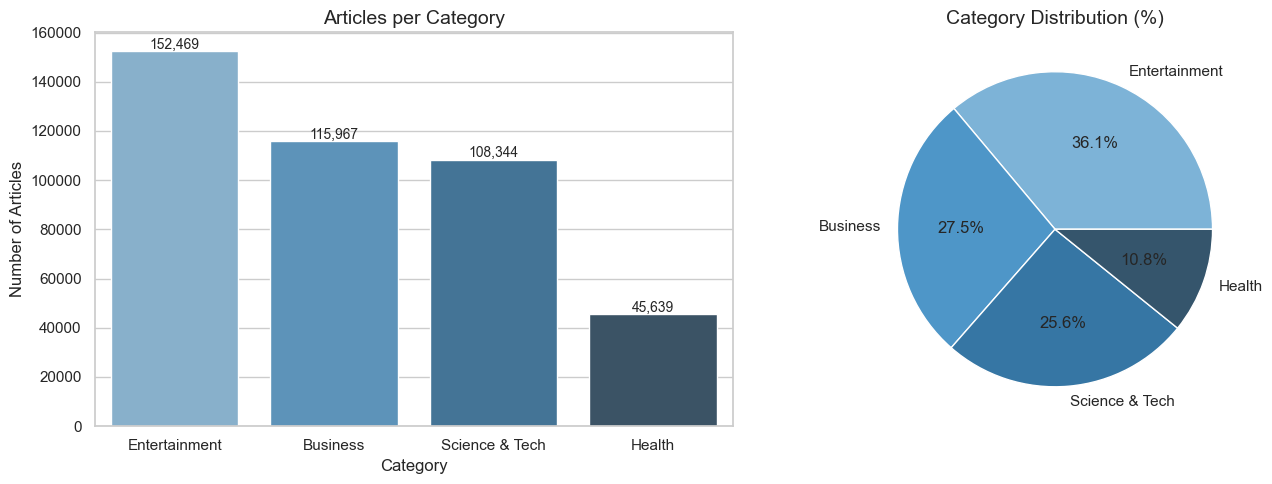

Chart saved!


In [6]:
# ============================================================
# STEP 4: VISUALISE CATEGORY DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart — count per category
category_counts_named = df["category_name"].value_counts()
sns.barplot(
    x=category_counts_named.index,
    y=category_counts_named.values,
    palette="Blues_d",
    ax=axes[0]
)
axes[0].set_title("Articles per Category", fontsize=14)
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Number of Articles")

# Add count labels on bars
for i, v in enumerate(category_counts_named.values):
    axes[0].text(i, v + 1000, f"{v:,}", ha="center", fontsize=10)

# Pie chart — percentage per category
axes[1].pie(
    category_counts_named.values,
    labels=category_counts_named.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("Blues_d", 4)
)
axes[1].set_title("Category Distribution (%)", fontsize=14)

plt.tight_layout()
plt.savefig("../data/processed/category_distribution.png")
plt.show()
print("Chart saved!")

/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_78104/1253554338.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


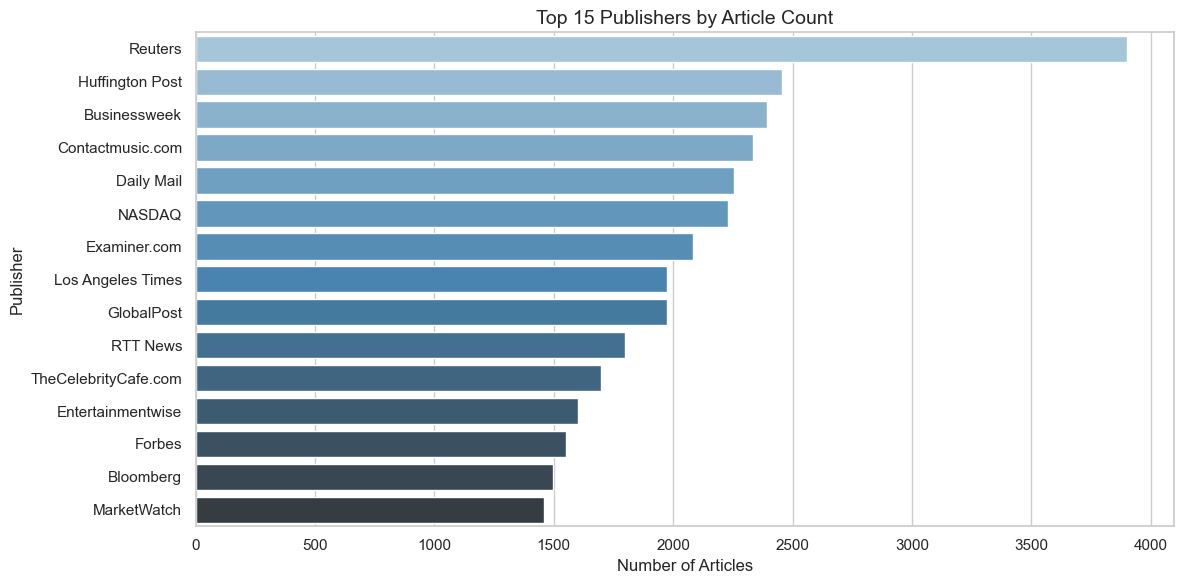


Total unique publishers: 10,985


In [7]:
# ============================================================
# STEP 5: EXPLORE PUBLISHERS
# ============================================================
# Who publishes the most articles in this dataset?
# This is the kind of analysis Upscore does for their clients!

top_publishers = df["PUBLISHER"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_publishers.values,
    y=top_publishers.index,
    palette="Blues_d"
)
plt.title("Top 15 Publishers by Article Count", fontsize=14)
plt.xlabel("Number of Articles")
plt.ylabel("Publisher")
plt.tight_layout()
plt.savefig("../data/processed/top_publishers.png")
plt.show()

print(f"\nTotal unique publishers: {df['PUBLISHER'].nunique():,}")

In [8]:
# ============================================================
# STEP 6: EXPLORE ARTICLE TITLES
# ============================================================
# The TITLE column is what we will use for NLP in notebook 02
# Let's understand what it looks like

print("=== SAMPLE TITLES PER CATEGORY ===\n")

for code, name in category_map.items():
    print(f"--- {name} ---")

    # Get 3 random titles from this category
    samples = df[df["CATEGORY"] == code]["TITLE"].sample(3, random_state=42)

    for title in samples:
        print(f"  • {title}")
    print()

# Title length analysis
df["title_length"] = df["TITLE"].str.len()

print("=== TITLE LENGTH STATS ===")
print(df["title_length"].describe().round(1))

=== SAMPLE TITLES PER CATEGORY ===

--- Business ---
  • Manufacturing grows at fastest pace since February
  • AT&T Could Strike $50 Billion Deal for DirecTV -- Update
  • Target Reports 16% Drop in Earnings -- 3rd Update

--- Science & Tech ---
  • Google announces same-day delivery service in New York and Los Angeles
  • Over 800000 Honda Odysseys Recalled Because of Fiery Death Risk
  • 'Blood moon' shines before eclipse

--- Entertainment ---
  • Mila & Ashton's Baby Joy!
  • Slasher attacks Japan pop girl group AKB48 at fan event
  • 'The Hobbit' Part 3 News: First Official Teaser Trailer For 'The Battle of the Five  ...

--- Health ---
  • Florida officials: Watch out for flesh-eating bacteria
  • Stem cell scientist wants report pulled
  • Unintended danger from antidepressant warnings

=== TITLE LENGTH STATS ===
count    422419.0
mean         56.8
std          81.9
min           4.0
25%          45.0
50%          56.0
75%          69.0
max       28426.0
Name: title_length, dty

/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_78104/1692180.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


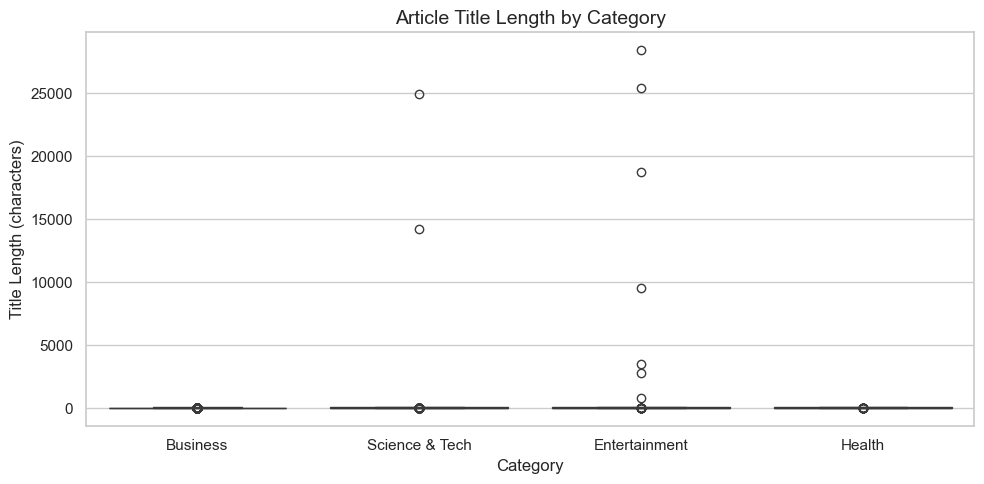

In [9]:
# ============================================================
# STEP 7: TITLE LENGTH BY CATEGORY
# ============================================================

plt.figure(figsize=(10, 5))
sns.boxplot(
    x="category_name",
    y="title_length",
    data=df,
    palette="Blues"
)
plt.title("Article Title Length by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Title Length (characters)")
plt.tight_layout()
plt.savefig("../data/processed/title_length_by_category.png")
plt.show()

In [10]:
# ============================================================
# STEP 8: SAVE CLEANED DATA FOR NEXT NOTEBOOKS
# ============================================================
import os

# Create processed folder if it doesn't exist
os.makedirs("../data/processed", exist_ok=True)

# Select only the columns we need
df_clean = df[["TITLE", "CATEGORY", "category_name",
               "PUBLISHER", "title_length"]].copy()

# Rename columns to lowercase for cleanliness
df_clean.columns = ["title", "category", "category_name",
                    "publisher", "title_length"]

# Remove any rows with missing titles
df_clean = df_clean.dropna(subset=["title"])

# Save to disk
df_clean.to_csv("../data/processed/news_clean.csv", index=False)

print(f"Saved cleaned data: {df_clean.shape[0]:,} articles")
print(f"Saved to: ../data/processed/news_clean.csv")

Saved cleaned data: 422,419 articles
Saved to: ../data/processed/news_clean.csv


In [12]:
# ============================================================
# SUMMARY — WHAT DID WE LEARN?
# ============================================================

print("=== EDA SUMMARY ===")
print(f"Total articles    : {df_clean.shape[0]:,}")
print(f"Total publishers  : {df_clean['publisher'].nunique():,}")
print(f"Categories        : {df_clean['category_name'].unique().tolist()}")
print(f"Avg title length  : {df_clean['title_length'].mean():.0f} characters")

print("""
WHAT HAPPENS NEXT?
------------------
Now we understand the data!

Next step is NLP — we use TF-IDF to convert article
titles into features and train a classifier to
automatically assign topics to new articles.

See notebook 02_nlp_topics.ipynb!
""")

=== EDA SUMMARY ===
Total articles    : 422,419
Total publishers  : 10,985
Categories        : ['Business', 'Science & Tech', 'Entertainment', 'Health']
Avg title length  : 57 characters

WHAT HAPPENS NEXT?
------------------
Now we understand the data!

Next step is NLP — we use TF-IDF to convert article
titles into features and train a classifier to
automatically assign topics to new articles.

See notebook 02_nlp_topics.ipynb!

